(569, 31)
   diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0          1        17.99         10.38          122.80     1001.0   
1          1        20.57         17.77          132.90     1326.0   
2          1        19.69         21.25          130.00     1203.0   
3          1        11.42         20.38           77.58      386.1   
4          1        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   symmetry_mean  ...  radius_worst  texture_worst  perimeter_worst  \
0         0.2419  ...         25.38

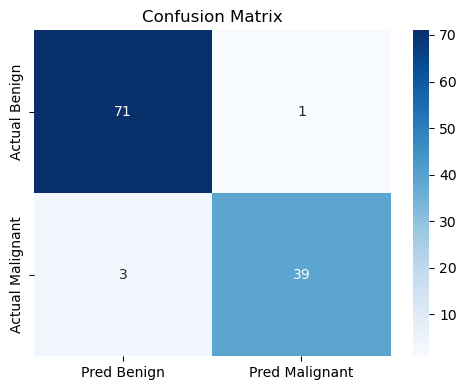

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, classification_report, accuracy_score,
    precision_score, recall_score, f1_score, roc_auc_score
)

# -------------------------
# 1. LOAD DATA FROM THE CSV
# -------------------------
df = pd.read_csv(r"C:\Users\user\Downloads\archive (9)\data.csv")

df = df.drop(columns=["id", "Unnamed: 32"], errors="ignore")
df["diagnosis"] = df["diagnosis"].map({"M": 1, "B": 0})  # Malignant = 1 (positive)

print(df.shape)
print(df.head())
print("\nClass balance (1 = malignant):\n", df['diagnosis'].value_counts())
print("\nMissing values:", df.isnull().sum().sum())


# ----------------------------------------
# 2. FEATURES / TARGET + TRAIN-TEST SPLIT
# ----------------------------------------
X = df.drop(columns="diagnosis")
y = df["diagnosis"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y          # keep the same malignant/benign ratio in train and test
)
# --------------------
# 3. BUILD THE MODEL  (scale -> logistic regression)
# --------------------
model = Pipeline([
    ('scaler', StandardScaler()),          # mean 0, std 1 for every feature
    ('logreg', LogisticRegression(max_iter=1000)),
])
model.fit(X_train, y_train)

# --------------------
# 4. PREDICT
# --------------------
y_pred = model.predict(X_test)              # labels 0/1 using threshold 0.5
y_prob = model.predict_proba(X_test)[:, 1]  # probability of malignant

# --------------------
# 5. EVALUATE
# --------------------
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print(f"\nConfusion matrix:\n", cm)
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")

print("\nAccuracy  : ", round(accuracy_score(y_test, y_pred), 4))
print("Precision : ", round(precision_score(y_test, y_pred), 4))
print("Recall    : ", round(recall_score(y_test, y_pred), 4))
print("F1-score  : ", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC   : ", round(roc_auc_score(y_test, y_prob), 4))

print("\nFull report:\n", classification_report(y_test, y_pred, target_names=["Benign", "Malignant"]))
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Pred Benign", "Pred Malignant"],
            yticklabels=["Actual Benign", "Actual Malignant"])
plt.title("Confusion Matrix")
plt.tight_layout()
plt.savefig("confusion_matrix.png")
plt.show()

In [9]:
#------------------------------------------------------
#
#-----------------------------------------------------------------
coef_df = pd.DataFrame({
    "feature": X.columns,
    "coefficient": model.named_steps["logreg"].coef_[0],
}).sort_values("coefficient", ascending=False)
print("\nTop 5 features pushing towards MALIGNANT:\n", coef_df.head(5))
print("\nTop 5 features pushing towards BENIGN:\n", coef_df.tail(5))


Top 5 features pushing towards MALIGNANT:
                 feature  coefficient
21        texture_worst     1.429023
10            radius_se     1.237079
28       symmetry_worst     1.062661
7   concave points_mean     0.948610
13              area_se     0.913437

Top 5 features pushing towards BENIGN:
                  feature  coefficient
18           symmetry_se    -0.332383
11            texture_se    -0.408740
5       compactness_mean    -0.441220
19  fractal_dimension_se    -0.591392
15        compactness_se    -0.907620


In [10]:
#------------------------------------------------------
#7.THRESHOLD EXPERIMENT (precision/recall trade-off)
#-----------------------------------------------------------------
print("\nThreshold  Precision  Recall   F1")
for t in [0.1, 0.3, 0.5, 0.7, 0.9]:
    pred_t = (y_prob >= t).astype(int)
    print(f"{t:.1f}        {precision_score(y_test, pred_t, zero_division=0):.3f}      "
          f"{recall_score(y_test, pred_t):.3f}    {f1_score(y_test, pred_t):.3f}")


Threshold  Precision  Recall   F1
0.1        0.891      0.976    0.932
0.3        0.976      0.976    0.976
0.5        0.975      0.929    0.951
0.7        1.000      0.905    0.950
0.9        1.000      0.786    0.880
